# Capstone Project: Anomaly Detection Absensi Tutor (Mumtaz Bimbel)
## TAHAP 1: Ekstraksi 19 Fitur Angka & Pelabelan (`features_dataset.csv`)

### 1.1 Persiapan Library & Upload Dataset Mentah
Pada sel ini, kita mengimpor library bawaan Python & Data Science, memastikan `lightgbm` dan `xgboost` terinstal di Google Colab, lalu memuat file `sessions_with_synthetic.csv` (7.557 baris, 10 kolom mentah) untuk diperiksa kelengkapan datanya.

In [1]:
# Menginstal library ML terlebih dahulu agar siap dipakai di Tahap 2 nanti
!pip install -q lightgbm xgboost scikit-learn joblib matplotlib seaborn

import os
import json
from datetime import datetime
from collections import defaultdict
import numpy as np
import pandas as pd

# Jika file belum ada di direktori sesi Colab, munculkan tombol upload otomatis
CSV_INPUT_PATH = "sessions_with_synthetic.csv"
if not os.path.exists(CSV_INPUT_PATH):
    from google.colab import files
    print("Silakan pilih dan upload file 'sessions_with_synthetic.csv'...")
    uploaded = files.upload()

# Membaca dataset mentah
df_raw = pd.read_csv(CSV_INPUT_PATH)

# Menampilkan informasi dimensi dan mengecek apakah ada nilai kosong (null/NaN)
print("=== INFORMASI DATASET MENTAH ===")
print(f"Jumlah Baris & Kolom : {df_raw.shape[0]} baris x {df_raw.shape[1]} kolom")
print("\nJumlah Nilai Kosong (Null) per Kolom:")
print(df_raw.isnull().sum())

# Validasi tegas (assert) bahwa jumlah baris tepat 7.557 dan bebas dari nilai null
assert len(df_raw) == 7557, f"Error: Jumlah baris harus 7557, terbaca {len(df_raw)}"
assert df_raw.isnull().sum().sum() == 0, "Error: Ditemukan nilai kosong (null)!"

# Menampilkan 5 baris pertama untuk memastikan struktur kolom sesuai spesifikasi
display(df_raw.head())

=== INFORMASI DATASET MENTAH ===
Jumlah Baris & Kolom : 7557 baris x 10 kolom

Jumlah Nilai Kosong (Null) per Kolom:
id                  0
tutor_id            0
student_id          0
subject_ids         0
lesson_date         0
start_time          0
duration_minutes    0
submitted_at        0
is_synthetic        0
scenario            0
dtype: int64


,id,tutor_id,student_id,subject_ids,lesson_date,start_time,duration_minutes,submitted_at,is_synthetic,scenario
0,473dc277-7a6e-47b7-a706-cca10a52bbd5,6daa16aa-6e13-430f-8fab-fd153fa48628,862cdfac-370d-493e-a3d7-0104f4c56ebf,"[""8cee3629-d670-4cc6-91ca-b0949f8a93d7""]",2025-06-16,19:00,60,2025-06-16T13:23:48Z,0,real
1,2681a729-6e41-4976-8d6c-f41b409c6a02,147fa0de-0977-4169-abb6-979a3624001a,7071ce8f-4f70-4453-ba17-2ad091cc1d30,"[""8cee3629-d670-4cc6-91ca-b0949f8a93d7""]",2025-08-27,14:00,60,2025-08-29T12:24:31Z,0,real
2,31284822-d7bc-47b3-a9d7-2021d6c60457,1bd2f250-45ee-4a90-a4c3-72c876bc9360,edd1a52b-965a-409c-a4b3-58a653c9586e,"[""d9b33948-782f-4255-b93f-07a85f6d1cbf""]",2025-09-19,15:30,60,2025-09-19T10:52:52Z,0,real
3,fde58aab-e836-48ad-a306-ff667a577f07,b552e93b-e148-4379-8bac-39849a140486,223be389-d59e-4792-b41e-0157223bae51,"[""8cee3629-d670-4cc6-91ca-b0949f8a93d7""]",2025-08-14,16:00,60,2025-08-14T10:24:16Z,0,real
4,1eadfe54-e313-4952-99b8-55804f59b5b3,7cfcd3c0-190e-4a02-b1fc-5847fc8d0d9c,501b8451-dfb5-405a-8ea7-43bbbe7fc30f,"[""8cee3629-d670-4cc6-91ca-b0949f8a93d7"", ""d9b3...",2025-06-15,15:00,60,2025-06-17T09:25:45Z,0,real


### 1.2 Definisi Urutan 19 Fitur Baku (`FEATURE_NAMES`) & Parsing Tipe Data
Model Machine Learning tidak dapat membaca teks UUID atau string JSON mentah. Pada sel ini kita:
1. Mendeklarasikan konstanta `FEATURE_NAMES` (19 fitur dengan urutan baku untuk kontrak FastAPI).
2. Mengubah `subject_ids` dari teks JSON menjadi `tuple` UUID yang sudah diurutkan (`sorted`).
3. Mengubah `start_time` (`"HH:MM"`) menjadi total menit sejak pukul `00:00` (`start_minute`) beserta `end_minute = start_minute + duration_minutes` untuk pengecekan jadwal bentrok (*overlap*).
4. Mengubah `lesson_date` (`"YYYY-MM-DD"`) menjadi objek `datetime.date` agar selisih `+-30 hari` bisa dihitung secara matematis.

In [2]:
# Daftar urutan 19 fitur numerik baku (JANGAN DIUBAH URUTANNYA agar sesuai kontrak FastAPI)
FEATURE_NAMES = [
    # No. 1 - 5: Fitur langsung dari target & config
    "duration_minutes",                  # 1. Lama les dalam menit
    "duration_over_limit",               # 2. duration_minutes - 180 (> 0 berarti melanggar batas atas)
    "start_minute",                      # 3. Jam mulai dalam menit sejak 00:00 (misal 14:00 = 840)
    "start_over_limit",                  # 4. start_minute - 1260 (> 0 berarti lewat pukul 21:00)
    "subject_count",                     # 5. Banyaknya mata pelajaran (1-5 mapel)
    # No. 6 - 13: Fitur hasil perbandingan dengan comparisons (+-30 hari)
    "comparisons_count",                 # 6. Total sesi riwayat pembanding (+-30 hari, maks 500)
    "exact_dup_count",                   # 7. Duplikat 100% persis 6 atribut (>= 1 -> rejected)
    "same_tutor_student_date_count",     # 8. Tutor, murid, dan tanggal sama
    "same_student_date_diff_tutor_count",# 9. Murid & tanggal sama, mapel beririsan, tutor berbeda
    "time_overlap_count",                # 10. Total jadwal bertabrakan di tanggal sama (tutor/murid sama)
    "tutor_sessions_30d",                # 11. Jumlah sesi milik tutor yang sama dalam +-30 hari
    "student_sessions_30d",              # 12. Jumlah sesi milik murid yang sama dalam +-30 hari
    "duration_diff_from_tutor_mean_30d", # 13. Selisih durasi dari rata-rata durasi tutor tsb (0 jika kosong)
    # No. 14 - 19: 6 Fitur tambahan revisi terbaru
    "duration_under_limit",              # 14. 30 - duration_minutes (> 0 berarti durasi < 30 menit)
    "start_under_limit",                 # 15. 420 - start_minute (> 0 berarti mulai sebelum 07:00)
    "fuzzy_dup_count",                   # 16. 5 atribut sama persis tetapi start_time berbeda
    "tutor_overlap_diff_student_count",  # 17. Tanggal sama, tutor sama, murid beda, jam bertabrakan
    "student_overlap_diff_tutor_count",  # 18. Tanggal sama, murid sama, tutor beda, jam bertabrakan
    "self_overlap_count",                # 19. Tanggal sama, tutor & murid sama, jam tabrakan, bukan exact dup
]

# Konstanta ambang batas sesuai objek config di FastAPI
CONFIG_DEFAULT = {
    "durationOutlierMinutes": 180,
    "durationMinMinutes": 30,
    "lateStartAfter": "21:00",   # 21 * 60 = 1260 menit
    "earlyStartBefore": "07:00", # 7 * 60 = 420 menit
    "comparisonWindowDays": 30,
    "maxComparisons": 500,
}

# Melakukan parsing seluruh baris CSV ke dalam list dictionary Python agar pencarian cepat
parsed_records = []
for row in df_raw.itertuples(index=False):
    # Mengubah jam mulai "HH:MM" menjadi menit sejak 00:00
    hh, mm = map(int, row.start_time.split(":"))
    start_min = hh * 60 + mm
    dur_min = int(row.duration_minutes)

    # Mengubah string JSON subject_ids menjadi tuple terurut dan set (untuk cek irisan mapel)
    subj_tuple = tuple(sorted(json.loads(row.subject_ids)))

    parsed_records.append({
        "id": row.id,
        "tutor_id": row.tutor_id,
        "student_id": row.student_id,
        "subject_ids": subj_tuple,
        "subject_set": set(subj_tuple),
        "lesson_date": datetime.strptime(row.lesson_date, "%Y-%m-%d").date(),
        "start_time": row.start_time,
        "start_minute": start_min,
        "end_minute": start_min + dur_min,
        "duration_minutes": dur_min,
        "submitted_at": row.submitted_at,
        "is_synthetic": int(row.is_synthetic),
        "scenario": row.scenario,
    })

print(f"Berhasil melakukan parsing {len(parsed_records)} baris sesi.")
print("Contoh hasil parsing baris ke-1:\n", parsed_records[0])

Berhasil melakukan parsing 7557 baris sesi.
Contoh hasil parsing baris ke-1:
 {'id': '473dc277-7a6e-47b7-a706-cca10a52bbd5', 'tutor_id': '6daa16aa-6e13-430f-8fab-fd153fa48628', 'student_id': '862cdfac-370d-493e-a3d7-0104f4c56ebf', 'subject_ids': ('8cee3629-d670-4cc6-91ca-b0949f8a93d7',), 'subject_set': {'8cee3629-d670-4cc6-91ca-b0949f8a93d7'}, 'lesson_date': datetime.date(2025, 6, 16), 'start_time': '19:00', 'start_minute': 1140, 'end_minute': 1200, 'duration_minutes': 60, 'submitted_at': '2025-06-16T13:23:48Z', 'is_synthetic': 0, 'scenario': 'real'}


### 1.3 – 1.5 Pencarian `comparisons`, Perhitungan 19 Fitur, & Penentuan Label `validity`
Untuk setiap baris sesi (`target`), kita mencari daftar sesi riwayat pembanding (`comparisons`) dengan 4 syarat:
1. Bukan dirinya sendiri (`other.id != target.id`).
2. Memiliki `tutor_id` yang sama **ATAU** `student_id` yang sama.
3. Berada dalam rentang waktu **+-30 hari** dari `target.lesson_date`.
4. Di-*submit* lebih awal (`other.submitted_at < target.submitted_at`, atau jika timestamp sama persis menggunakan *tie-breaker* `other.id < target.id`), diurutkan dari yang paling awal dan dibatasi maksimal **500 sesi**.

Setelah 19 fitur dihitung, label target `validity` ditentukan mengikuti hierarki prioritas mutlak: **`rejected` > `needs_revision` > `valid`**.

In [3]:
# Membuat indeks lookup berdasarkan tutor_id dan student_id
# Tujuannya agar pencarian comparisons tidak perlu looping 7.557 x 7.557 penuh (selesai < 2 detik)
by_tutor = defaultdict(list)
by_student = defaultdict(list)

for idx, rec in enumerate(parsed_records):
    by_tutor[rec["tutor_id"]].append(idx)
    by_student[rec["student_id"]].append(idx)

extracted_rows = []

# Looping untuk setiap baris sesi sebagai 'target'
for idx, target in enumerate(parsed_records):
    # Mengambil kandidat sesi yang memiliki tutor_id SAMA atau student_id SAMA
    candidate_indices = set(by_tutor[target["tutor_id"]]) | set(by_student[target["student_id"]])

    comparisons = []
    for o_idx in candidate_indices:
        # Syarat 1: Bukan dirinya sendiri
        if o_idx == idx:
            continue
        other = parsed_records[o_idx]

        # Syarat 2: Rentang tanggal les maksimal +-30 hari
        if abs((other["lesson_date"] - target["lesson_date"]).days) <= 30:
            # Syarat 3: Dikirim lebih awal (submitted_at lebih kecil, tie-breaker dengan id)
            if (other["submitted_at"] < target["submitted_at"]) or (
                other["submitted_at"] == target["submitted_at"] and other["id"] < target["id"]
            ):
                comparisons.append(other)

    # Syarat 4: Urutkan dari submitted_at paling awal dan batasi maksimal 500 sesi
    comparisons.sort(key=lambda x: (x["submitted_at"], x["id"]))
    comparisons = comparisons[:500]

    # =========================================================================
    # A. HITUNG FITUR DARI TARGET & CONFIG (Fitur No. 1-5 dan No. 14-15)
    # =========================================================================
    duration_minutes = target["duration_minutes"]
    duration_over_limit = duration_minutes - 180     # > 0 berarti durasi > 180 menit
    start_minute = target["start_minute"]
    start_over_limit = start_minute - 1260           # > 0 berarti mulai lewat 21:00 (1260)
    subject_count = len(target["subject_ids"])
    duration_under_limit = 30 - duration_minutes     # > 0 berarti durasi < 30 menit
    start_under_limit = 420 - start_minute           # > 0 berarti mulai sebelum 07:00 (420)

    # =========================================================================
    # B. HITUNG FITUR DARI PERBANDINGAN TARGET VS COMPARISONS (No. 6-13 & 16-19)
    # =========================================================================
    comparisons_count = len(comparisons)
    exact_dup_count = 0
    same_tutor_student_date_count = 0
    same_student_date_diff_tutor_count = 0
    time_overlap_count = 0
    tutor_sessions_30d = 0
    student_sessions_30d = 0
    tutor_durations = []

    fuzzy_dup_count = 0
    tutor_overlap_diff_student_count = 0
    student_overlap_diff_tutor_count = 0
    self_overlap_count = 0

    for comp in comparisons:
        # Pengecekan kesamaan atribut dasar antara target dan sesi pembanding (comp)
        same_tutor = (comp["tutor_id"] == target["tutor_id"])
        same_student = (comp["student_id"] == target["student_id"])
        same_subjects = (comp["subject_ids"] == target["subject_ids"])
        subj_intersect = len(comp["subject_set"] & target["subject_set"]) > 0
        same_date = (comp["lesson_date"] == target["lesson_date"])
        same_start = (comp["start_time"] == target["start_time"])
        same_duration = (comp["duration_minutes"] == target["duration_minutes"])

        # Fitur 11 & persiapan Fitur 13: Frekuensi & daftar durasi tutor yang sama dalam +-30 hari
        if same_tutor:
            tutor_sessions_30d += 1
            tutor_durations.append(comp["duration_minutes"])

        # Fitur 12: Frekuensi les murid yang sama dalam +-30 hari
        if same_student:
            student_sessions_30d += 1

        # Fitur 7: Duplikat Persis (6 atribut sama persis)
        is_exact_dup = (
            same_tutor and same_student and same_subjects and
            same_date and same_start and same_duration
        )
        if is_exact_dup:
            exact_dup_count += 1

        # Fitur 16: Duplikat Samar (5 atribut sama persis, tetapi start_time berbeda)
        if (same_tutor and same_student and same_subjects and
            same_date and same_duration and not same_start):
            fuzzy_dup_count += 1

        # Fitur 8: Tutor, murid, dan tanggal les sama
        if same_tutor and same_student and same_date:
            same_tutor_student_date_count += 1

        # Fitur 9: Murid dan tanggal sama, mata pelajaran beririsan, tetapi tutor berbeda
        if same_student and same_date and (not same_tutor) and subj_intersect:
            same_student_date_diff_tutor_count += 1

        # Pengecekan Jadwal Bertabrakan (Overlap) di tanggal yang sama
        # Rumus Overlap: start_A < end_B DAN start_B < end_A
        if same_date:
            is_overlap = (
                (target["start_minute"] < comp["end_minute"]) and
                (comp["start_minute"] < target["end_minute"])
            )
            if is_overlap and (same_tutor or same_student):
                # Fitur 10: Total jadwal bertabrakan (semua jenis)
                time_overlap_count += 1

                # Fitur 17: Jadwal tutor bentrok dengan murid lain di tanggal yang sama
                if same_tutor and not same_student:
                    tutor_overlap_diff_student_count += 1
                # Fitur 18: Jadwal murid bentrok dengan tutor lain di tanggal yang sama
                elif same_student and not same_tutor:
                    student_overlap_diff_tutor_count += 1
                # Fitur 19: Jadwal tutor & murid yang sama bentrok, tapi bukan duplikat persis
                elif same_tutor and same_student and not is_exact_dup:
                    self_overlap_count += 1

    # Fitur 13: Selisih durasi target terhadap rata-rata durasi tutor dalam +-30 hari
    if len(tutor_durations) > 0:
        tutor_mean_30d = sum(tutor_durations) / len(tutor_durations)
        duration_diff_from_tutor_mean_30d = round(duration_minutes - tutor_mean_30d, 4)
    else:
        duration_diff_from_tutor_mean_30d = 0.0

    # =========================================================================
    # C. PENENTUAN LABEL TARGET (validity) SESUAI HIERARKI PRIORITAS BISNIS
    # Urutan Prioritas: rejected > needs_revision > valid
    # =========================================================================
    if exact_dup_count >= 1:
        validity = "rejected"
    elif (
        duration_over_limit > 0 or
        duration_under_limit > 0 or
        start_over_limit > 0 or
        start_under_limit > 0 or
        fuzzy_dup_count >= 1 or
        tutor_overlap_diff_student_count >= 1 or
        student_overlap_diff_tutor_count >= 1 or
        self_overlap_count >= 1
    ):
        validity = "needs_revision"
    else:
        validity = "valid"

    # Menyimpan baris hasil ekstraksi (id + 19 fitur urut + validity + metadata evaluasi)
    extracted_rows.append({
        "id": target["id"],
        "duration_minutes": duration_minutes,
        "duration_over_limit": duration_over_limit,
        "start_minute": start_minute,
        "start_over_limit": start_over_limit,
        "subject_count": subject_count,
        "comparisons_count": comparisons_count,
        "exact_dup_count": exact_dup_count,
        "same_tutor_student_date_count": same_tutor_student_date_count,
        "same_student_date_diff_tutor_count": same_student_date_diff_tutor_count,
        "time_overlap_count": time_overlap_count,
        "tutor_sessions_30d": tutor_sessions_30d,
        "student_sessions_30d": student_sessions_30d,
        "duration_diff_from_tutor_mean_30d": duration_diff_from_tutor_mean_30d,
        "duration_under_limit": duration_under_limit,
        "start_under_limit": start_under_limit,
        "fuzzy_dup_count": fuzzy_dup_count,
        "tutor_overlap_diff_student_count": tutor_overlap_diff_student_count,
        "student_overlap_diff_tutor_count": student_overlap_diff_tutor_count,
        "self_overlap_count": self_overlap_count,
        "validity": validity,
        "is_synthetic": target["is_synthetic"],
        "scenario": target["scenario"],
    })

# Membentuk DataFrame fitur hasil Tahap 1
df_features = pd.DataFrame(extracted_rows)
print(f"Ekstraksi 19 fitur selesai! Bentuk tabel: {df_features.shape}")

Ekstraksi 19 fitur selesai! Bentuk tabel: (7557, 23)


### 1.6 Verifikasi Kunci Distribusi Label & Penyimpanan `features_dataset.csv`
Sebelum lanjut ke Tahap 2, kita wajib memverifikasi bahwa jumlah label `validity` yang terbentuk sama persis dengan kunci verifikasi di dokumen spesifikasi:
- **`valid`:** `4.534` baris (`60.00%`)
- **`needs_revision`:** `1.511` baris (`19.99%`)
- **`rejected`:** `1.512` baris (`20.01%`)

Catatan: Kolom `is_synthetic` dan `scenario` tetap disimpan di dalam `features_dataset.csv` khusus untuk evaluasi per skenario pada akhir Tahap 2, namun **tidak akan dimasukkan** ke dalam matriks fitur `X` saat melatih model.

In [4]:
# Mengecek distribusi kelas validity hasil ekstraksi
label_counts = df_features["validity"].value_counts()
label_pcts = (label_counts / len(df_features) * 100).round(2)

print("=== HASIL VERIFIKASI DISTRIBUSI LABEL VALIDITY ===")
for label_name in ["valid", "needs_revision", "rejected"]:
    cnt = label_counts.get(label_name, 0)
    pct = label_pcts.get(label_name, 0.0)
    print(f"- {label_name:15s}: {cnt:4d} baris ({pct:.2f}%)")

# Validasi tegas (assert) terhadap kunci verifikasi wajib (4534 / 1511 / 1512)
assert label_counts["valid"] == 4534, f"Meleset! valid={label_counts['valid']}, seharusnya 4534"
assert label_counts["needs_revision"] == 1511, f"Meleset! needs_revision={label_counts['needs_revision']}, seharusnya 1511"
assert label_counts["rejected"] == 1512, f"Meleset! rejected={label_counts['rejected']}, seharusnya 1512"
assert df_features[FEATURE_NAMES].isnull().sum().sum() == 0, "Ada nilai NaN pada fitur!"

print("\n✅ VERIFIKASI TAHAP 1 LULUS 100%! Angka sama persis dengan spesifikasi.")

# Menampilkan tabel silang (crosstab) antara scenario dan validity
print("\n=== DISTRIBUSI LABEL PER SKENARIO (15 SKENARIO) ===")
display(pd.crosstab(df_features["scenario"], df_features["validity"], margins=True))

# Menyimpan dataset fitur ke file CSV
FEATURES_CSV_PATH = "features_dataset.csv"
df_features.to_csv(FEATURES_CSV_PATH, index=False)
print(f"\nFile '{FEATURES_CSV_PATH}' berhasil disimpan ({df_features.shape[0]} baris x {df_features.shape[1]} kolom).")

=== HASIL VERIFIKASI DISTRIBUSI LABEL VALIDITY ===
- valid          : 4534 baris (60.00%)
- needs_revision : 1511 baris (19.99%)
- rejected       : 1512 baris (20.01%)

✅ VERIFIKASI TAHAP 1 LULUS 100%! Angka sama persis dengan spesifikasi.

=== DISTRIBUSI LABEL PER SKENARIO (15 SKENARIO) ===


validity,needs_revision,rejected,valid,All
scenario,,,,
batas_valid,0,0,100,100
duplikat,0,1273,0,1273
duplikat_samar,128,0,0,128
durasi_panjang,128,0,0,128
durasi_pendek,128,0,0,128
kombinasi_dup_malam,50,50,0,100
kombinasi_dup_pagi,50,50,0,100
kombinasi_dup_panjang,50,50,0,100
kombinasi_dup_pendek,50,50,0,100



File 'features_dataset.csv' berhasil disimpan (7557 baris x 23 kolom).


## TAHAP 2: Training, Evaluasi, & Export Model ML

### 2.1 Pemisahan Data (*Stratified Train / Validation / Test Split* — 70% / 15% / 15%)
Pada sel ini kita memisahkan matriks fitur `X` dan target `y`:
- **`X` hanya berisi 19 kolom `FEATURE_NAMES`**. Kolom `id`, `is_synthetic`, dan `scenario` **dikecualikan** dari `X` agar tidak terjadi *data leakage* dan sesuai dengan input FastAPI di produksi.
- Pembagian data menggunakan **Stratified Split** (`stratify=y`, `random_state=42`) dengan proporsi **70% Train (5.289 baris)**, **15% Validation (1.134 baris)**, dan **15% Test (1.134 baris)** agar rasio kelas `60% : 20% : 20%` terjaga di setiap bagian data.

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Membaca kembali features_dataset.csv untuk memastikan pipeline Tahap 2 mandiri
df_model = pd.read_csv("features_dataset.csv")

# Tahap Split 1: Pisahkan 70% Data Train dan 30% Data Sementara (Validation + Test)
df_train, df_temp = train_test_split(
    df_model,
    test_size=0.30,
    stratify=df_model["validity"],
    random_state=42
)

# Tahap Split 2: Bagi rata 30% Data Sementara menjadi 15% Validation dan 15% Test
df_val, df_test = train_test_split(
    df_temp,
    test_size=0.50,
    stratify=df_temp["validity"],
    random_state=42
)

# Mengambil HANYA 19 fitur numerik (FEATURE_NAMES) sebagai matriks X
# Kolom id, is_synthetic, dan scenario TIDAK dimasukkan ke X
X_train = df_train[FEATURE_NAMES].copy()
y_train = df_train["validity"].copy()

X_val = df_val[FEATURE_NAMES].copy()
y_val = df_val["validity"].copy()

X_test = df_test[FEATURE_NAMES].copy()
y_test = df_test["validity"].copy()

# Menyiapkan LabelEncoder khusus untuk XGBoost (karena XGBoost mewajibkan target integer 0, 1, 2)
label_encoder = LabelEncoder()
y_train_enc = label_encoder.fit_transform(y_train)
y_val_enc = label_encoder.transform(y_val)
y_test_enc = label_encoder.transform(y_test)

print("=== UKURAN DATA HASIL STRATIFIED SPLIT ===")
print(f"1. Train Set      : {len(df_train):4d} baris ({len(df_train)/len(df_model)*100:.1f}%)")
print(f"2. Validation Set : {len(df_val):4d} baris ({len(df_val)/len(df_model)*100:.1f}%)")
print(f"3. Test Set       : {len(df_test):4d} baris ({len(df_test)/len(df_model)*100:.1f}%)")

# Menampilkan tabel proporsi kelas di setiap split untuk membuktikan stratifikasi berhasil
split_summary = pd.DataFrame({
    "Train (70%)": y_train.value_counts(),
    "Train %": (y_train.value_counts(normalize=True) * 100).round(2),
    "Val (15%)": y_val.value_counts(),
    "Val %": (y_val.value_counts(normalize=True) * 100).round(2),
    "Test (15%)": y_test.value_counts(),
    "Test %": (y_test.value_counts(normalize=True) * 100).round(2),
})
display(split_summary)

=== UKURAN DATA HASIL STRATIFIED SPLIT ===
1. Train Set      : 5289 baris (70.0%)
2. Validation Set : 1134 baris (15.0%)
3. Test Set       : 1134 baris (15.0%)


,Train (70%),Train %,Val (15%),Val %,Test (15%),Test %
validity,,,,,,
needs_revision,1058,20.00,226,19.93,227,20.02
rejected,1058,20.00,227,20.02,227,20.02
valid,3173,59.99,681,60.05,680,59.96


### 2.2 Pelatihan 3 Kandidat Model (*Random Forest*, *XGBoost*, & *LightGBM*)
Kita melatih dan membandingkan 3 algoritma klasifikasi berbasis pohon keputusan (*tree-based ensemble*) yang unggul pada data tabular dengan batas keputusan tajam (*sharp threshold*):
1. **Random Forest Classifier (`scikit-learn`):** Model *bagging ensemble* paralel sebagai *baseline*.
2. **XGBoost Classifier (`xgboost`):** Model *depth-wise gradient boosting* dengan regularisasi.
3. **LightGBM Classifier (`lightgbm`):** Model *leaf-wise gradient boosting* yang ringan dan cepat (kandidat utama).

In [6]:
import time
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
import xgboost as xgb
import lightgbm as lgb

# 1. Inisialisasi Model 1: Random Forest (Baseline)
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

# 2. Inisialisasi Model 2: XGBoost
xgb_model = xgb.XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    eval_metric="mlogloss",
    n_jobs=-1
)

# 3. Inisialisasi Model 3: LightGBM (Kandidat Utama)
lgb_model = lgb.LGBMClassifier(
    n_estimators=200,
    random_state=42,
    verbose=-1,
    n_jobs=-1
)

# Melatih ketiga model hanya pada Data Train (X_train) dan mencatat waktu latihnya
trained_models = {}
predictions_val = {}
predictions_test = {}
comparison_rows = []

# --- A. Latih Random Forest (langsung menggunakan label string) ---
t0 = time.time()
rf_model.fit(X_train, y_train)
rf_time = time.time() - t0
trained_models["Random Forest"] = rf_model
predictions_val["Random Forest"] = rf_model.predict(X_val)
predictions_test["Random Forest"] = rf_model.predict(X_test)

# --- B. Latih XGBoost (menggunakan label angka y_train_enc lalu dikembalikan ke string) ---
t0 = time.time()
xgb_model.fit(X_train, y_train_enc)
xgb_time = time.time() - t0
trained_models["XGBoost"] = xgb_model
predictions_val["XGBoost"] = label_encoder.inverse_transform(xgb_model.predict(X_val))
predictions_test["XGBoost"] = label_encoder.inverse_transform(xgb_model.predict(X_test))

# --- C. Latih LightGBM (langsung menggunakan label string) ---
t0 = time.time()
lgb_model.fit(X_train, y_train)
lgb_time = time.time() - t0
trained_models["LightGBM"] = lgb_model
predictions_val["LightGBM"] = lgb_model.predict(X_val)
predictions_test["LightGBM"] = lgb_model.predict(X_test)

# Menyusun tabel perbandingan metrik di Validation Set dan Test Set
for model_name, train_sec in [("Random Forest", rf_time), ("XGBoost", xgb_time), ("LightGBM", lgb_time)]:
    val_p = predictions_val[model_name]
    test_p = predictions_test[model_name]

    comparison_rows.append({
        "Model": model_name,
        "Waktu Latih (detik)": round(train_sec, 3),
        "Val Accuracy": round(accuracy_score(y_val, val_p), 6),
        "Val Macro Precision": round(precision_score(y_val, val_p, average="macro"), 6),
        "Val Macro Recall": round(recall_score(y_val, val_p, average="macro"), 6),
        "Val Macro F1": round(f1_score(y_val, val_p, average="macro"), 6),
        "Test Accuracy": round(accuracy_score(y_test, test_p), 6),
        "Test Macro F1": round(f1_score(y_test, test_p, average="macro"), 6),
    })

df_comparison = pd.DataFrame(comparison_rows)
print("=== TABEL PERBANDINGAN PERFORMA 3 KANDIDAT MODEL ===")
display(df_comparison)

=== TABEL PERBANDINGAN PERFORMA 3 KANDIDAT MODEL ===


,Model,Waktu Latih (detik),Val Accuracy,Val Macro Precision,Val Macro Recall,Val Macro F1,Test Accuracy,Test Macro F1
0,Random Forest,0.459,0.999118,0.999511,0.998525,0.999016,0.999118,0.999019
1,XGBoost,0.793,0.999118,0.999511,0.998525,0.999016,1.000000,1.000000
2,LightGBM,0.383,0.999118,0.999511,0.998525,0.999016,1.000000,1.000000


### 2.3a & 2.3b Evaluasi Metrik per Kelas (*Classification Report*) & *Confusion Matrix* 3x3
Pada sel ini kita menampilkan:
1. **Classification Report (Precision, Recall, F1-Score)** untuk setiap kelas (`valid`, `needs_revision`, `rejected`) pada data *Test*. Fokus utama bisnis adalah memastikan **Recall pada `rejected` dan `needs_revision` mendekati 100%** agar tidak ada absen bermasalah yang lolos menjadi `valid` dan ikut terbayar di rekap gaji.
2. **Plot Heatmap Confusion Matrix 3x3** untuk ketiga model berdampingan.

CLASSIFICATION REPORT (TEST SET - 1.134 BARIS) — MODEL: LightGBM
                precision    recall  f1-score   support

         valid     1.0000    1.0000    1.0000       680
needs_revision     1.0000    1.0000    1.0000       227
      rejected     1.0000    1.0000    1.0000       227

      accuracy                         1.0000      1134
     macro avg     1.0000    1.0000    1.0000      1134
  weighted avg     1.0000    1.0000    1.0000      1134

CLASSIFICATION REPORT (TEST SET - 1.134 BARIS) — MODEL: XGBoost
                precision    recall  f1-score   support

         valid     1.0000    1.0000    1.0000       680
needs_revision     1.0000    1.0000    1.0000       227
      rejected     1.0000    1.0000    1.0000       227

      accuracy                         1.0000      1134
     macro avg     1.0000    1.0000    1.0000      1134
  weighted avg     1.0000    1.0000    1.0000      1134

CLASSIFICATION REPORT (TEST SET - 1.134 BARIS) — MODEL: Random Forest
           

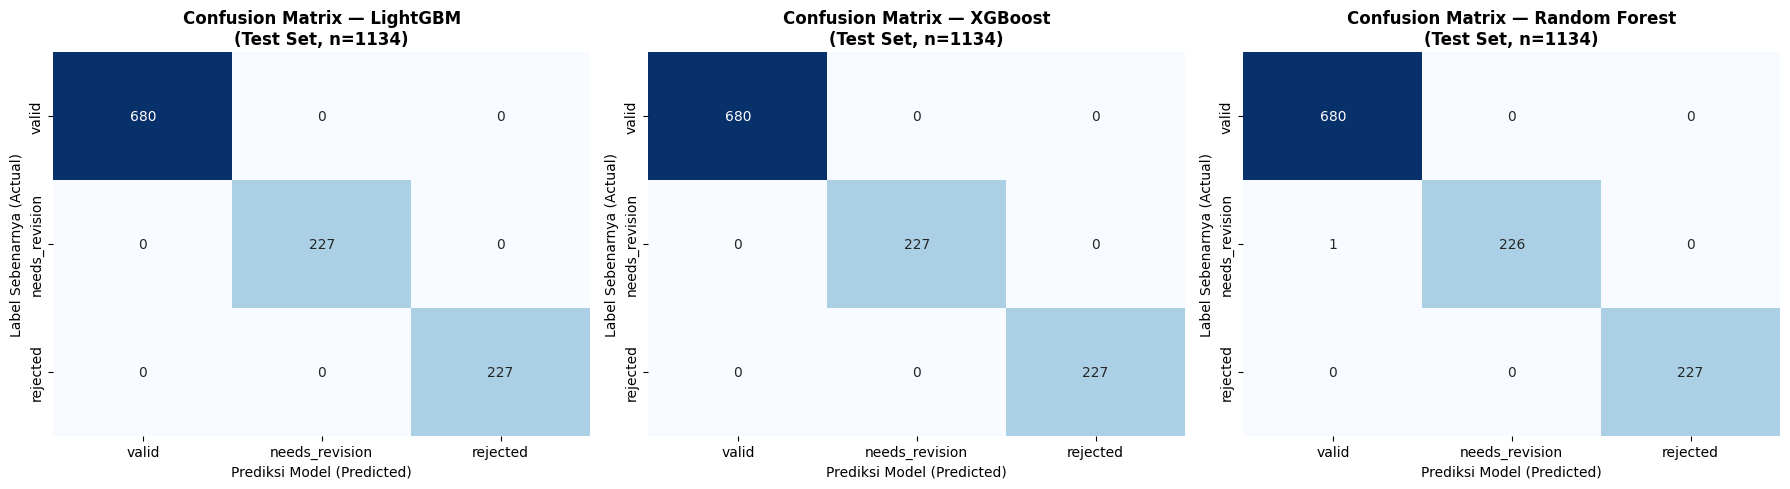

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

CLASS_ORDER = ["valid", "needs_revision", "rejected"]

# 1. Mencetak Classification Report lengkap untuk ketiga model pada Test Set
for model_name in ["LightGBM", "XGBoost", "Random Forest"]:
    print("=" * 70)
    print(f"CLASSIFICATION REPORT (TEST SET - 1.134 BARIS) — MODEL: {model_name}")
    print("=" * 70)
    print(classification_report(
        y_test,
        predictions_test[model_name],
        labels=CLASS_ORDER,
        digits=4
    ))

# 2. Menggambar Heatmap Confusion Matrix 3x3 untuk ketiga model
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, model_name in zip(axes, ["LightGBM", "XGBoost", "Random Forest"]):
    cm = confusion_matrix(y_test, predictions_test[model_name], labels=CLASS_ORDER)
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=CLASS_ORDER,
        yticklabels=CLASS_ORDER,
        ax=ax,
        cbar=False
    )
    ax.set_title(f"Confusion Matrix — {model_name}\n(Test Set, n={len(y_test)})", fontsize=12, fontweight="bold")
    ax.set_xlabel("Prediksi Model (Predicted)", fontsize=10)
    ax.set_ylabel("Label Sebenarnya (Actual)", fontsize=10)

plt.tight_layout()
plt.savefig("confusion_matrix_comparison.png", dpi=150)
plt.show()

### 2.3c Evaluasi Akurasi per Skenario (`scenario`) & Kasus Batas (`batas_valid`)
Di sinilah kolom `scenario` dan `is_synthetic` yang tadi kita simpan di `df_test` digunakan. Kita mengelompokkan hasil prediksi data *Test* ke dalam 15 skenario uji untuk membuktikan bahwa model:
1. Tidak salah memprediksi di garis batas (`batas_valid`: durasi tepat `30` atau `180` menit, jam mulai tepat `07:00` atau `21:00`).
2. Menerapkan hierarki prioritas dengan benar pada ke-4 skenario kombinasi (`kombinasi_dup_panjang`, `kombinasi_dup_pendek`, `kombinasi_dup_malam`, `kombinasi_dup_pagi`).

In [8]:
# Memilih model terbaik berdasarkan nilai Validation Macro F1 tertinggi (default ke LightGBM jika seri)
best_model_name = df_comparison.sort_values(
    by=["Val Macro F1", "Test Macro F1"], ascending=False
).iloc[0]["Model"]

# Jika LightGBM memiliki skor setara/terbaik, kita prioritaskan LightGBM sesuai rencana arsitektur
if df_comparison.loc[df_comparison["Model"] == "LightGBM", "Val Macro F1"].values[0] >= (
    df_comparison["Val Macro F1"].max() - 0.001
):
    best_model_name = "LightGBM"

print(f"🌟 Model Terbaik Terpilih untuk Evaluasi Skenario & Deployment: {best_model_name}")

# Menggabungkan prediksi model terbaik dengan metadata scenario di Test Set
df_eval_test = df_test[["id", "scenario", "is_synthetic", "validity"]].copy()
df_eval_test["predicted"] = predictions_test[best_model_name]
df_eval_test["is_correct"] = (df_eval_test["validity"] == df_eval_test["predicted"])

# Membuat tabel ringkasan akurasi per skenario pada Test Set
scenario_eval = (
    df_eval_test.groupby(["is_synthetic", "scenario"])
    .agg(
        total_sampel_test=("is_correct", "count"),
        prediksi_benar=("is_correct", "sum"),
        prediksi_salah=("is_correct", lambda x: (~x).sum()),
        akurasi_persen=("is_correct", lambda x: round(x.mean() * 100, 2))
    )
    .reset_index()
)

print(f"\n=== TABEL AKURASI PER SKENARIO PADA TEST SET (MODEL: {best_model_name}) ===")
display(scenario_eval)

# Menampilkan detail jika ada baris yang meleset pada Test Set untuk dianalisis
misclassified = df_eval_test[~df_eval_test["is_correct"]]
print(f"\nTotal baris meleset di Test Set: {len(misclassified)} dari {len(df_eval_test)} baris.")
if len(misclassified) > 0:
    display(df_test.loc[misclassified.index, ["id", "scenario", "validity"] + FEATURE_NAMES[:10]])

🌟 Model Terbaik Terpilih untuk Evaluasi Skenario & Deployment: LightGBM

=== TABEL AKURASI PER SKENARIO PADA TEST SET (MODEL: LightGBM) ===


,is_synthetic,scenario,total_sampel_test,prediksi_benar,prediksi_salah,akurasi_persen
0,0,real,721,721,0,100.0
1,1,batas_valid,9,9,0,100.0
2,1,duplikat,191,191,0,100.0
3,1,duplikat_samar,25,25,0,100.0
4,1,durasi_panjang,15,15,0,100.0
5,1,durasi_pendek,21,21,0,100.0
6,1,kombinasi_dup_malam,8,8,0,100.0
7,1,kombinasi_dup_pagi,17,17,0,100.0
8,1,kombinasi_dup_panjang,12,12,0,100.0
9,1,kombinasi_dup_pendek,18,18,0,100.0



Total baris meleset di Test Set: 0 dari 1134 baris.


### 2.3d Evaluasi Tingkat Kepentingan Fitur (*Feature Importance*)
Grafik ini menjawab pertanyaan penguji sidang *capstone* mengenai fitur mana dari ke-19 fitur yang paling berkontribusi dalam pengambilan keputusan model AI (bukan *black-box*).

=== PERINGKAT 19 FITUR (FEATURE IMPORTANCE — LightGBM) ===


,No_Fitur,Nama_Fitur,Importance
0,#3,start_minute,2412
1,#1,duration_minutes,1447
2,#13,duration_diff_from_tutor_mean_30d,752
3,#6,comparisons_count,746
4,#15,start_under_limit,661
5,#11,tutor_sessions_30d,488
6,#4,start_over_limit,458
7,#10,time_overlap_count,391
8,#14,duration_under_limit,369
9,#16,fuzzy_dup_count,339


/tmp/ipykernel_433/214375496.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


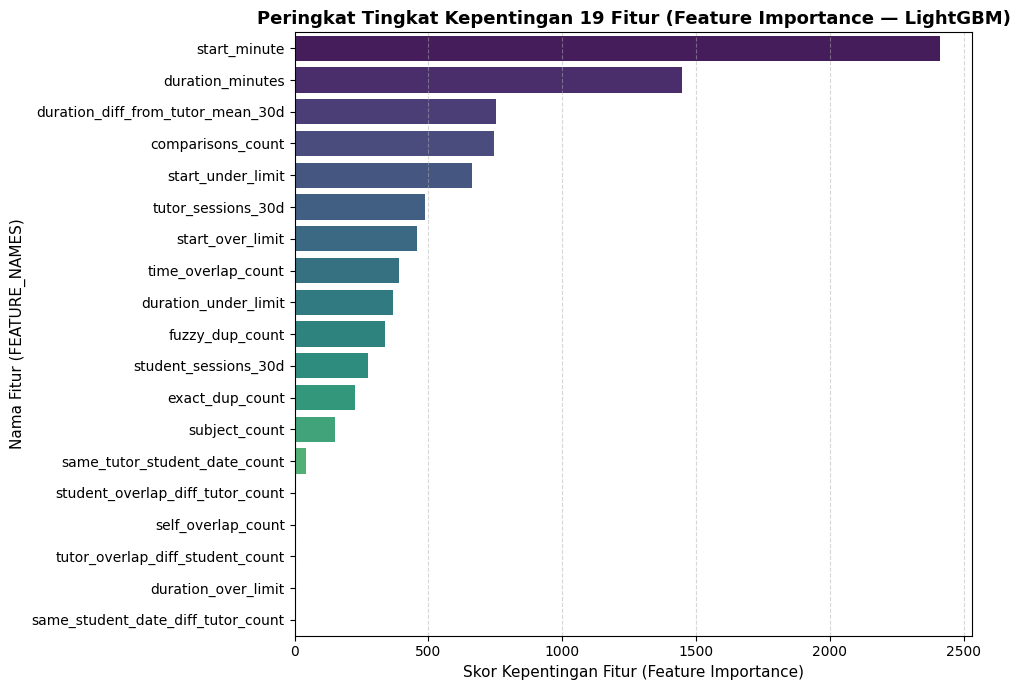

In [9]:
# Mengambil nilai feature_importances_ dari model terbaik
best_model_obj = trained_models[best_model_name]
importances = best_model_obj.feature_importances_

# Membentuk DataFrame peringkat fitur dari yang paling berpengaruh
df_importance = pd.DataFrame({
    "No_Fitur": [f"#{i+1}" for i in range(len(FEATURE_NAMES))],
    "Nama_Fitur": FEATURE_NAMES,
    "Importance": importances
}).sort_values(by="Importance", ascending=False).reset_index(drop=True)

print(f"=== PERINGKAT 19 FITUR (FEATURE IMPORTANCE — {best_model_name}) ===")
display(df_importance)

# Membuat visualisasi Horizontal Bar Chart untuk laporan Capstone
plt.figure(figsize=(10, 7))
sns.barplot(
    data=df_importance,
    x="Importance",
    y="Nama_Fitur",
    palette="viridis"
)
plt.title(f"Peringkat Tingkat Kepentingan 19 Fitur (Feature Importance — {best_model_name})", fontsize=13, fontweight="bold")
plt.xlabel("Skor Kepentingan Fitur (Feature Importance)", fontsize=11)
plt.ylabel("Nama Fitur (FEATURE_NAMES)", fontsize=11)
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("feature_importance_19_features.png", dpi=150)
plt.show()

### 2.4 Penyimpanan (*Export*) `anomaly_model.pkl` & `feature_metadata.json` untuk FastAPI
Pada sel terakhir ini kita:
1. Menyimpan model terbaik ke dalam file **`anomaly_model.pkl`** menggunakan `joblib.dump()`.
2. Menyimpan file **`feature_metadata.json`** yang berisi urutan baku 19 `FEATURE_NAMES`, daftar kelas target, nilai default `config`, dan metrik evaluasi model.
3. Menjalankan **uji coba simulasi prediksi 1 baris vektor 19 fitur** persis seperti cara layanan FastAPI memanggil `model.predict()` di produksi nanti, lalu mengunduh file artefak ke komputer lokal.

In [10]:
import joblib

MODEL_PKL_PATH = "anomaly_model.pkl"
METADATA_JSON_PATH = "feature_metadata.json"

# Catatan Penting:
# Agar di FastAPI nanti pemanggilan `model.predict([vektor_19_angka])` langsung mengembalikan
# string ("valid", "needs_revision", atau "rejected") sesuai dokumen spesifikasi Section 4.3,
# pastikan model yang disimpan adalah LightGBM atau Random Forest (yang dilatih langsung dengan label string).
export_model_name = best_model_name if best_model_name in ["LightGBM", "Random Forest"] else "LightGBM"
export_model = trained_models[export_model_name]

# 1. Simpan model ke file anomaly_model.pkl
joblib.dump(export_model, MODEL_PKL_PATH)

# 2. Susun dan simpan metadata fitur ke feature_metadata.json
metadata_payload = {
    "model_name": export_model_name,
    "feature_count": len(FEATURE_NAMES),
    "feature_names": FEATURE_NAMES,
    "target_classes": list(export_model.classes_),
    "priority_order": ["rejected", "needs_revision", "valid"],
    "default_config": CONFIG_DEFAULT,
    "dataset_summary": {
        "total_rows": int(len(df_model)),
        "train_rows": int(len(df_train)),
        "val_rows": int(len(df_val)),
        "test_rows": int(len(df_test)),
        "class_distribution": {
            "valid": int(label_counts["valid"]),
            "needs_revision": int(label_counts["needs_revision"]),
            "rejected": int(label_counts["rejected"]),
        },
    },
    "metrics_summary": df_comparison.loc[
        df_comparison["Model"] == export_model_name
    ].to_dict(orient="records")[0],
}

with open(METADATA_JSON_PATH, "w", encoding="utf-8") as f:
    json.dump(metadata_payload, f, indent=2, ensure_ascii=False)

print(f"✅ Model berhasil disimpan ke   : {MODEL_PKL_PATH} ({os.path.getsize(MODEL_PKL_PATH) / 1024:.1f} KB)")
print(f"✅ Metadata berhasil disimpan ke: {METADATA_JSON_PATH}")

# =========================================================================
# 3. SIMULASI UJI COBA KONTRAK FASTAPI (Sesuai Contoh Dokumen Section 4.3)
# =========================================================================
loaded_model = joblib.load(MODEL_PKL_PATH)

# Contoh vektor 19 fitur dari Dokumen Implementasi Section 4.3 (Kasus Duplikat Persis)
sample_vector = pd.DataFrame(
    [[60, -120, 840, -420, 1, 2, 1, 1, 0, 1, 2, 2, 0.0, -30, -420, 0, 0, 0, 0]],
    columns=FEATURE_NAMES
)
pred_class = loaded_model.predict(sample_vector)[0]
pred_proba = loaded_model.predict_proba(sample_vector)[0]

print("\n=== UJI SIMULASI PREDIKSI MODEL (.pkl) UNTUK FASTAPI ===")
print("Input 19 Fitur :", sample_vector.values.tolist()[0])
print("Hasil Prediksi :", pred_class)
print("Probabilitas   :", dict(zip(loaded_model.classes_, np.round(pred_proba, 4))))

# 4. Mengunduh artefak ke komputer lokal (otomatis berjalan jika di Google Colab)
try:
    from google.colab import files
    files.download(MODEL_PKL_PATH)
    files.download(METADATA_JSON_PATH)
    files.download(FEATURES_CSV_PATH)
except ImportError:
    print("\nFile tersimpan di direktori kerja lokal.")

✅ Model berhasil disimpan ke   : anomaly_model.pkl (1106.0 KB)
✅ Metadata berhasil disimpan ke: feature_metadata.json

=== UJI SIMULASI PREDIKSI MODEL (.pkl) UNTUK FASTAPI ===
Input 19 Fitur : [60.0, -120.0, 840.0, -420.0, 1.0, 2.0, 1.0, 1.0, 0.0, 1.0, 2.0, 2.0, 0.0, -30.0, -420.0, 0.0, 0.0, 0.0, 0.0]
Hasil Prediksi : rejected
Probabilitas   : {'needs_revision': np.float64(0.0), 'rejected': np.float64(1.0), 'valid': np.float64(0.0)}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>